# Import needed modules

In [1]:
# import system libs
import os
import shutil
import pathlib
import itertools

# import data handling tools
import cv2
import numpy as np
import pandas as pd
import seaborn as sns
sns.set_style('darkgrid')
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report

# import Deep learning Libraries
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.optimizers import Adam, Adamax
from tensorflow.keras.metrics import categorical_crossentropy
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Activation, Dropout, BatchNormalization
from tensorflow.keras import regularizers

# Ignore Warnings
import warnings
warnings.filterwarnings("ignore")

print ('modules loaded')

c:\Users\mh978\AppData\Local\Programs\Python\Python310\lib\site-packages\google\api_core\_python_version_support.py:275: FutureWarning: You are using a Python version (3.10.10) which Google will stop supporting in new releases of google.api_core once it reaches its end of life (2026-10-04). Please upgrade to the latest Python version, or at least Python 3.11, to continue receiving updates for google.api_core past that date.
  warnings.warn(message, FutureWarning)


modules loaded


# Create needed functions

## Functions to Create Data Frame from Dataset

#### **Function to create data frame**

In [2]:
# Generate data paths with labels  #dataset\diabetic_retinopathy\100_right.jpeg
def define_paths(data_dir):
    filepaths = []
    labels = []

    folds = os.listdir(data_dir) #ctatrac, diabetic_retinopathy, glaucoma, normal, retinopathy_of_prematurity
    for fold in folds:
        foldpath = os.path.join(data_dir, fold) 
        filelist = os.listdir(foldpath)
        for file in filelist:
            fpath = os.path.join(foldpath, file)
            filepaths.append(fpath)
            labels.append(fold)

    return filepaths, labels


# Concatenate data paths with labels into one dataframe ( to later be fitted into the model )
def define_df(files, classes):
    Fseries = pd.Series(files, name= 'filepaths')
    Lseries = pd.Series(classes, name='labels')
    return pd.concat([Fseries, Lseries], axis= 1)

# Split dataframe to train, valid, and test
def split_data(data_dir):
    # train dataframe
    files, classes = define_paths(data_dir)
    df = define_df(files, classes)
    strat = df['labels']
    train_df, dummy_df = train_test_split(df,  train_size= 0.8, shuffle= True, random_state= 123, stratify= strat)

    # valid and test dataframe
    strat = dummy_df['labels']
    valid_df, test_df = train_test_split(dummy_df,  train_size= 0.5, shuffle= True, random_state= 123, stratify= strat)

    return train_df, valid_df, test_df

#### Function to generate images from dataframe

In [3]:
def create_gens (train_df, valid_df, test_df, batch_size):
    '''
    This function takes train, validation, and test dataframe and fit them into image data generator, because model takes data from image data generator.
    Image data generator converts images into tensors. '''


    # define model parameters
    img_size = (224, 224)
    
    channels = 3 # either BGR or Grayscale
    color = 'rgb'
    img_shape = (img_size[0], img_size[1], channels)

    # Recommended : use custom function for test data batch size, else we can use normal batch size.
    ts_length = len(test_df)
    test_batch_size = max(sorted([ts_length // n for n in range(1, ts_length + 1) if ts_length%n == 0 and ts_length/n <= 80]))
    test_steps = ts_length // test_batch_size

    # This function which will be used in image data generator for data augmentation, it just take the image and return it again.
    def scalar(img):
        return img

    tr_gen = ImageDataGenerator(preprocessing_function= scalar, horizontal_flip= True)
    ts_gen = ImageDataGenerator(preprocessing_function= scalar)

    train_gen = tr_gen.flow_from_dataframe( train_df, x_col= 'filepaths', y_col= 'labels', target_size= img_size, class_mode= 'categorical',
                                        color_mode= color, shuffle= True, batch_size= batch_size)

    valid_gen = ts_gen.flow_from_dataframe( valid_df, x_col= 'filepaths', y_col= 'labels', target_size= img_size, class_mode= 'categorical',
                                        color_mode= color, shuffle= True, batch_size= batch_size)

    # Note: we will use custom test_batch_size, and make shuffle= false
    test_gen = ts_gen.flow_from_dataframe( test_df, x_col= 'filepaths', y_col= 'labels', target_size= img_size, class_mode= 'categorical',
                                        color_mode= color, shuffle= False, batch_size= test_batch_size)

    return train_gen, valid_gen, test_gen

#### **Function to display data sample**

In [4]:
def show_images(gen):
    '''
    This function take the data generator and show sample of the images
    '''

    # return classes , images to be displayed
    g_dict = gen.class_indices        # defines dictionary {'class': index}
    classes = list(g_dict.keys())     # defines list of dictionary's kays (classes), classes names : string
    images, labels = next(gen)        # get a batch size samples from the generator

    # calculate number of displayed samples
    length = len(labels)        # length of batch size
    sample = min(length, 25)    # check if sample less than 25 images

    plt.figure(figsize= (20, 20))

    for i in range(sample):
        plt.subplot(5, 5, i + 1)
        image = images[i] / 255       # scales data to range (0 - 255)
        plt.imshow(image)
        index = np.argmax(labels[i])  # get image index
        class_name = classes[index]   # get class of image
        plt.title(class_name, color= 'blue', fontsize= 12)
        plt.axis('off')
    plt.show()

#### **Function to plot history of training**

In [5]:
def plot_training(hist):
    '''
    This function take training model and plot history of accuracy and losses with the best epoch in both of them.
    '''

    # Define needed variables
    tr_acc = hist.history['accuracy']
    tr_loss = hist.history['loss']
    val_acc = hist.history['val_accuracy']
    val_loss = hist.history['val_loss']
    index_loss = np.argmin(val_loss)
    val_lowest = val_loss[index_loss]
    index_acc = np.argmax(val_acc)
    acc_highest = val_acc[index_acc]
    Epochs = [i+1 for i in range(len(tr_acc))]
    loss_label = f'best epoch= {str(index_loss + 1)}'
    acc_label = f'best epoch= {str(index_acc + 1)}'

    # Plot training history
    plt.figure(figsize= (20, 8))
    plt.style.use('fivethirtyeight')

    plt.subplot(1, 2, 1)
    plt.plot(Epochs, tr_loss, 'r', label= 'Training loss')
    plt.plot(Epochs, val_loss, 'g', label= 'Validation loss')
    plt.scatter(index_loss + 1, val_lowest, s= 150, c= 'blue', label= loss_label)
    plt.title('Training and Validation Loss')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend()

    plt.subplot(1, 2, 2)
    plt.plot(Epochs, tr_acc, 'r', label= 'Training Accuracy')
    plt.plot(Epochs, val_acc, 'g', label= 'Validation Accuracy')
    plt.scatter(index_acc + 1 , acc_highest, s= 150, c= 'blue', label= acc_label)
    plt.title('Training and Validation Accuracy')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy')
    plt.legend()

    plt.tight_layout
    plt.show()


#### **Function to create Confusion Matrix**

In [6]:
def plot_confusion_matrix(cm, classes, normalize= False, title= 'Confusion Matrix', cmap= plt.cm.Blues):
	'''
	This function plot confusion matrix method from sklearn package.
	'''

	plt.figure(figsize= (10, 10))
	plt.imshow(cm, interpolation= 'nearest', cmap= cmap)
	plt.title(title)
	plt.colorbar()

	tick_marks = np.arange(len(classes))
	plt.xticks(tick_marks, classes, rotation= 45)
	plt.yticks(tick_marks, classes)

	if normalize:
		cm = cm.astype('float') / cm.sum(axis= 1)[:, np.newaxis]
		print('Normalized Confusion Matrix')

	else:
		print('Confusion Matrix, Without Normalization')

	print(cm)

	thresh = cm.max() / 2.
	for i, j in itertools.product(range(cm.shape[0]), range(cm.shape[1])):
		plt.text(j, i, cm[i, j], horizontalalignment= 'center', color= 'white' if cm[i, j] > thresh else 'black')

	plt.tight_layout()
	plt.ylabel('True Label')
	plt.xlabel('Predicted Label')

# **Model Structure**

#### **Start Reading Dataset**

In [7]:
data_dir = 'dataset'

try:
    # Get splitted data
    train_df, valid_df, test_df = split_data(data_dir)

    # Get Generators
    batch_size = 8
    train_gen, valid_gen, test_gen = create_gens(train_df, valid_df, test_df, batch_size)

except Exception as e:
    print(f'Invalid Input: {e}')

Found 3373 validated image filenames belonging to 4 classes.
Found 422 validated image filenames belonging to 4 classes.
Found 422 validated image filenames belonging to 4 classes.


#### **Display Image Sample**

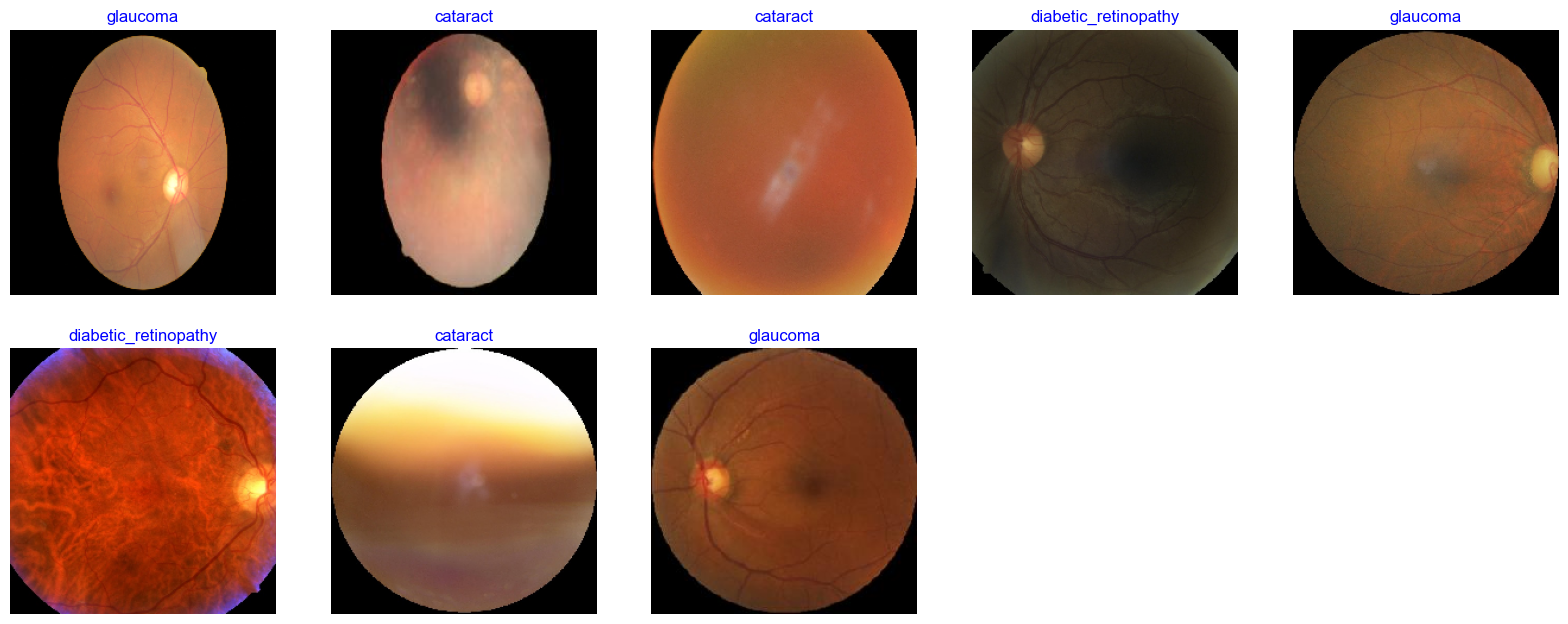

In [27]:
show_images(train_gen)

#### **Generic Model Creation**

In [8]:
# Create Model Structure
img_size = (224, 224)
channels = 3
img_shape = (img_size[0], img_size[1], channels) #224x224x3
class_count = len(list(train_gen.class_indices.keys())) # to define number of classes in dense layer

# create pre-trained model (you can built on pretrained model such as :  efficientnet, VGG , Resnet )
# we will use efficientnetb3 from EfficientNet family.
base_model = tf.keras.applications.efficientnet.EfficientNetB3(include_top= False, weights= "imagenet", input_shape= img_shape, pooling= 'max')
base_model.trainable = True

model = Sequential([
    base_model,
    BatchNormalization(axis= -1, momentum= 0.99, epsilon= 0.001),
    Dense(256, kernel_regularizer= regularizers.l2(l= 0.016), activity_regularizer= regularizers.l1(0.006),
                bias_regularizer= regularizers.l1(0.006), activation= 'relu'),
    Dropout(rate= 0.45, seed= 123),
    Dense(class_count, activation= 'softmax')
])

model.compile(Adamax(learning_rate= 0.001), loss= 'categorical_crossentropy', metrics= ['accuracy'])

model.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 efficientnetb3 (Functional)  (None, 1536)             10783535  
                                                                 
 batch_normalization (BatchN  (None, 1536)             6144      
 ormalization)                                                   
                                                                 
 dense (Dense)               (None, 256)               393472    
                                                                 
 dropout (Dropout)           (None, 256)               0         
                                                                 
 dense_1 (Dense)             (None, 4)                 1028      
                                                                 
Total params: 11,184,179
Trainable params: 11,093,804
Non-trainable params: 90,375
_______________________________________

#### **Set Training Parameters**

In [29]:
epochs = 40   # number of epochs to train


#### **Train model**

In [30]:
history = model.fit(
    x=train_gen,
    epochs=epochs,
    verbose=1,
    validation_data=valid_gen,
    validation_steps=None,
    shuffle=False
)

Epoch 1/40
422/422 [==============================] - 49s 93ms/step - loss: 7.1581 - accuracy: 0.6952 - val_loss: 5.3829 - val_accuracy: 0.8720
Epoch 2/40
422/422 [==============================] - 23s 54ms/step - loss: 4.7181 - accuracy: 0.7800 - val_loss: 3.6108 - val_accuracy: 0.8981
Epoch 3/40
422/422 [==============================] - 23s 55ms/step - loss: 3.1959 - accuracy: 0.8174 - val_loss: 2.4799 - val_accuracy: 0.9005
Epoch 4/40
422/422 [==============================] - 23s 55ms/step - loss: 2.2419 - accuracy: 0.8363 - val_loss: 1.7674 - val_accuracy: 0.8934
Epoch 5/40
422/422 [==============================] - 20s 48ms/step - loss: 1.6854 - accuracy: 0.8369 - val_loss: 1.3266 - val_accuracy: 0.9100
Epoch 6/40
422/422 [==============================] - 20s 48ms/step - loss: 1.3310 - accuracy: 0.8461 - val_loss: 1.0854 - val_accuracy: 0.9028
Epoch 7/40
422/422 [==============================] - 20s 48ms/step - loss: 1.1215 - accuracy: 0.8494 - val_loss: 0.9119 - val_accuracy:

#### **Display model performance**

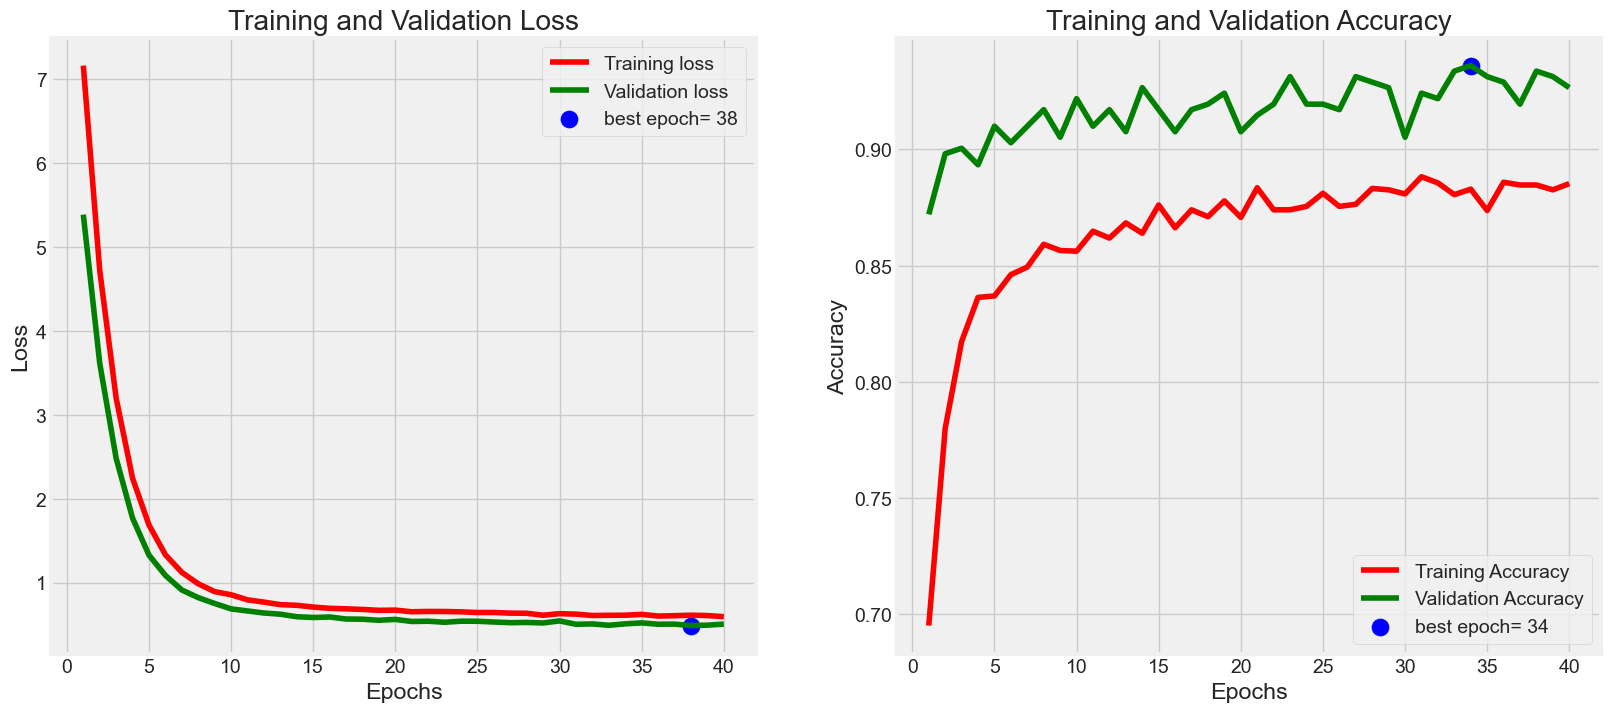

In [31]:
plot_training(history)

# **Evaluate model**

In [32]:
ts_length = len(test_df)
test_batch_size = test_batch_size = max(sorted([ts_length // n for n in range(1, ts_length + 1) if ts_length%n == 0 and ts_length/n <= 80]))
test_steps = ts_length // test_batch_size

train_score = model.evaluate(train_gen, steps= test_steps, verbose= 1)
valid_score = model.evaluate(valid_gen, steps= test_steps, verbose= 1)
test_score = model.evaluate(test_gen, steps= test_steps, verbose= 1)

print("Train Loss: ", train_score[0])
print("Train Accuracy: ", train_score[1])
print('-' * 20)
print("Validation Loss: ", valid_score[0])
print("Validation Accuracy: ", valid_score[1])
print('-' * 20)
print("Test Loss: ", test_score[0])
print("Test Accuracy: ", test_score[1])

211/211 [==============================] - 8s 35ms/step - loss: 0.5318 - accuracy: 0.9076
Train Loss:  0.43566814064979553
Train Accuracy:  0.9555687308311462
--------------------
Validation Loss:  0.5058159828186035
Validation Accuracy:  0.9265402555465698
--------------------
Test Loss:  0.5318446755409241
Test Accuracy:  0.9075829386711121


# **Get Predictions**

In [33]:
preds = model.predict_generator(test_gen)
y_pred = np.argmax(preds, axis=1)
print(y_pred)

[1 2 2 3 2 1 3 3 0 2 1 3 2 1 3 3 0 2 3 1 3 0 2 1 2 0 2 3 1 2 1 3 1 1 2 2 1
 3 0 2 1 0 2 0 1 2 1 1 2 1 0 3 2 1 1 1 2 0 2 1 3 0 3 1 0 0 0 0 2 1 2 0 1 1
 1 2 2 0 1 1 2 2 0 0 3 3 1 2 3 0 0 2 0 1 2 0 2 1 3 3 3 3 0 2 0 3 0 0 1 2 3
 1 1 3 3 3 0 1 0 2 2 2 2 1 0 3 2 0 0 2 0 2 3 2 0 1 2 1 0 1 1 3 0 0 1 0 3 1
 2 3 1 0 3 3 2 2 2 0 2 1 3 3 3 3 0 0 0 2 0 0 0 2 2 2 1 0 0 2 1 3 1 0 3 0 0
 0 0 1 3 2 0 1 2 3 0 3 1 3 3 2 0 1 1 3 0 3 1 1 1 1 3 3 1 3 2 2 2 0 1 3 0 2
 0 1 0 3 0 2 3 3 3 0 2 2 1 2 3 0 3 0 1 0 1 0 3 1 3 3 3 1 0 3 1 3 2 3 3 0 1
 3 1 1 3 0 0 2 1 3 3 1 2 1 1 0 1 1 0 3 2 1 3 0 3 3 1 3 1 2 2 1 0 2 3 3 1 1
 3 1 3 2 2 3 3 1 2 1 2 1 2 0 0 0 3 3 2 1 0 1 3 3 1 0 3 1 3 0 0 3 0 2 1 0 1
 1 3 0 0 0 1 0 0 1 0 2 2 2 1 3 1 3 1 1 0 1 1 2 1 1 2 0 1 0 1 1 3 2 1 1 3 2
 3 0 3 2 1 3 0 3 3 3 2 1 3 1 1 3 3 1 2 2 1 3 0 2 2 0 0 2 0 2 2 3 0 0 2 1 2
 0 0 0 2 1 3 0 0 3 1 3 1 2 0 3]


#### **Confusion Matrics and Classification Report**

Confusion Matrix, Without Normalization
[[ 99   0   3   2]
 [  0 109   1   0]
 [  5   3  82  11]
 [  2   3   9  93]]
                      precision    recall  f1-score   support

            cataract       0.93      0.95      0.94       104
diabetic_retinopathy       0.95      0.99      0.97       110
            glaucoma       0.86      0.81      0.84       101
              normal       0.88      0.87      0.87       107

            accuracy                           0.91       422
           macro avg       0.91      0.91      0.91       422
        weighted avg       0.91      0.91      0.91       422



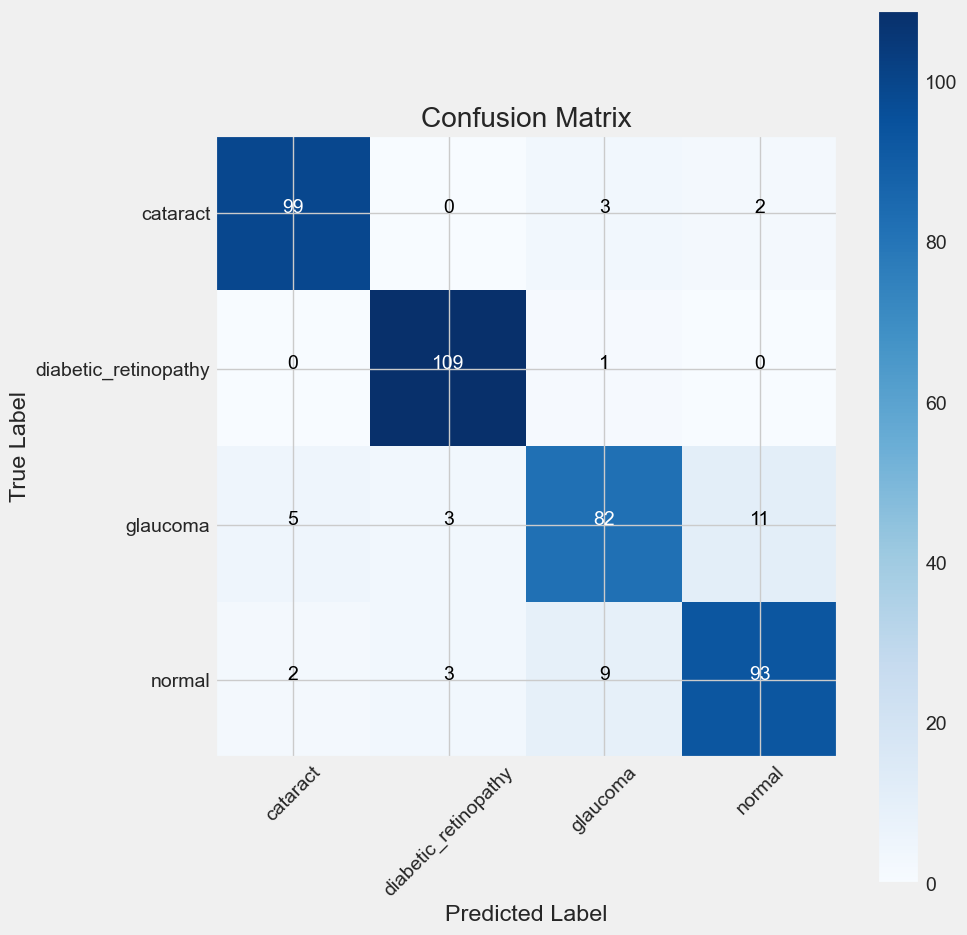

In [34]:
g_dict = test_gen.class_indices
classes = list(g_dict.keys())

# Confusion matrix
cm = confusion_matrix(test_gen.classes, y_pred)
plot_confusion_matrix(cm= cm, classes= classes, title = 'Confusion Matrix')

# Classification report
print(classification_report(test_gen.classes, y_pred, target_names= classes))

#### **Save model**

In [35]:
model_name = model.input_names[0][:-6]
subject = 'Eye Disease'
acc = test_score[1] * 100
save_path = ''

# Save model
save_id = str(f'{model_name}-{subject}-{"%.2f" %round(acc, 2)}.h5')
model_save_loc = os.path.join(save_path, save_id)
model.save(model_save_loc)
print(f'model was saved as {model_save_loc}')

# Save weights
weight_save_id = str(f'{model_name}-{subject}-weights.h5')
weights_save_loc = os.path.join(save_path, weight_save_id)
model.save_weights(weights_save_loc)
print(f'weights were saved as {weights_save_loc}')

model was saved as efficientnetb3-Eye Disease-90.76.h5
weights were saved as efficientnetb3-Eye Disease-weights.h5
